# Практическая работа №7
## Самостоятельная работа — три класса CIFAR-10

**Задача — построить, обучить и проверить одну CNN на своей части CIFAR-10.**
Используйте ту же последовательность действий, которая разобрана на BloodMNIST.
Объекты из памяти другого блокнота не нужны.

| Вариант | Коды исходных классов | Классы |
|---|---|---|
| 1 | 0, 1, 8 | Самолёт, автомобиль, корабль |
| 2 | 2, 4, 6 | Птица, олень, лягушка |
| 3 | 3, 5, 7 | Кошка, собака, лошадь |
| 4 | 1, 8, 9 | Автомобиль, корабль, грузовик |
| 5 | 0, 2, 7 | Самолёт, птица, лошадь |

Для каждого класса отбираются 1500 обучающих, 300 проверочных и 300 тестовых изображений.
Обучающая часть содержит 1500 объектов.
Исходный CIFAR-10 имеет размер 32 × 32 [1].
Уменьшение до 28×28 выполняется явно в `Resize`.

### 1. Импорт и устройство

При отсутствии пакетов выполните установку и перезапустите ядро.

```python
%pip install torch torchvision numpy pandas matplotlib scikit-learn
```

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn, optim
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

torch.set_num_threads(2)
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print("PyTorch", torch.__version__, "Устройство", device)

PyTorch 2.9.1+cpu Устройство cpu


### 2. Выберите свой вариант

Измените только значение `variant`.
Затем перезапустите этот блокнот сверху вниз.
Исходные номера классов будут заменены на `0`, `1`, `2` в том же порядке, в каком они записаны в `selected_classes`.

In [3]:
variant = 1
variants = {1: [0, 1, 8], 2: [2, 4, 6], 3: [3, 5, 7],
            4: [1, 8, 9], 5: [0, 2, 7]}
selected_classes = variants[variant]
all_names = ["Самолёт", "Автомобиль", "Птица", "Кошка", "Олень",
             "Собака", "Лягушка", "Лошадь", "Корабль", "Грузовик"]
class_names = [all_names[i] for i in selected_classes]
display(pd.DataFrame({"Исходный код": selected_classes,
                      "Новый код": [0, 1, 2], "Класс": class_names}))

,Исходный код,Новый код,Класс
0,0,0,Самолёт
1,1,1,Автомобиль
2,8,2,Корабль


### 3. Загрузите данные и задайте преобразования

`CIFAR10` уже реализует интерфейс `Dataset` [2].
Преобразования выполняются при запросе отдельного изображения.
В режиме без интернета заранее поместите распакованную папку `cifar-10-batches-py` в каталог `practice8_data`.

In [4]:
image_transform = transforms.Compose([
    transforms.Resize((28, 28), antialias=True),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])
cifar_train_source = datasets.CIFAR10(
    root="practice8_data", train=True, download=True, transform=image_transform
)
cifar_test_source = datasets.CIFAR10(
    root="practice8_data", train=False, download=True, transform=image_transform
)

100%|██████████| 170M/170M [16:40<00:00, 170kB/s]    


### 4. Отберите объекты своего варианта

После случайной перестановки `cifar_train_source` первые 1500 индексов класса должны попасть в `train`.
Следующие 300 идут в `valid`.
Объекты `test` выбираются из другого исходного набора.
Таким образом, один исходный объект не используется одновременно в обучении и проверке.

In [8]:
import random
from collections import defaultdict

random.seed(42)
variant = 1
variants = {1: [0, 1, 8], 2: [2, 4, 6], 3: [3, 5, 7], 4: [1, 8, 9], 5: [0, 2, 7]}
selected_classes = variants[variant]

# Мы используем .targets — это встроенный список правильных ответов в датасете.
# Это работает мгновенно, так как не требует загрузки самих картинок.

# 1. Для обучающей части (1500 + 300)
class_indices = defaultdict(list)
for idx, label in enumerate(cifar_train_source.targets):
    if label in selected_classes:
        class_indices[label].append(idx)

split_indices = {"train": [], "valid": []}
for cls in selected_classes:
    random.shuffle(class_indices[cls])
    split_indices["train"].extend(class_indices[cls][:1500])
    split_indices["valid"].extend(class_indices[cls][1500:1800]) # 1500 + 300

# 2. Для тестовой части (300 на класс = 900 всего)
test_class_indices = defaultdict(list)
for idx, label in enumerate(cifar_test_source.targets):
    if label in selected_classes:
        test_class_indices[label].append(idx)

test_indices = {"test": []}
for cls in selected_classes:
    random.shuffle(test_class_indices[cls])
    test_indices["test"].extend(test_class_indices[cls][:300])

print(f"Train: {len(split_indices['train'])} | Valid: {len(split_indices['valid'])} | Test: {len(test_indices['test'])}")

Train: 4500 | Valid: 900 | Test: 900


### 5. Реализуйте Dataset и DataLoader

In [9]:
class CIFARSubset(Dataset):
    def __init__(self, base_dataset, indices, class_mapping):
        self.base = base_dataset
        self.indices = indices
        self.mapping = class_mapping # {0:0, 1:1, 8:2}

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, idx):
        img, original_label = self.base[self.indices[idx]]
        new_label = self.mapping[original_label] # Перекодируем 0,1,8 -> 0,1,2
        return img, new_label

# Словарь для перекодировки классов
class_mapping = {orig: new for new, orig in enumerate(selected_classes)}

train_data = CIFARSubset(cifar_train_source, split_indices["train"], class_mapping)
valid_data = CIFARSubset(cifar_train_source, split_indices["valid"], class_mapping)
test_data = CIFARSubset(cifar_test_source, test_indices["test"], class_mapping)

train_loader = DataLoader(train_data, batch_size=64, shuffle=True)
valid_loader = DataLoader(valid_data, batch_size=64, shuffle=False)
test_loader = DataLoader(test_data, batch_size=64, shuffle=False)

### 6. Создайте CNN с тремя выходами

In [10]:
class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(2)
        
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(2)
        
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(64 * 7 * 7, 128) # 28/2/2 = 7
        self.relu3 = nn.ReLU()
        self.fc2 = nn.Linear(128, 3) # 3 класса

    def forward(self, x):
        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))
        x = self.flatten(x)
        x = self.relu3(self.fc1(x))
        x = self.fc2(x)
        return x

model = SimpleCNN().to(device)
print(f"Параметров в модели: {sum(p.numel() for p in model.parameters() if p.requires_grad)}")

Параметров в модели: 421315


### 7. Выполните пять эпох обучения

Найдите в коде примера получение пакета, прямой проход, вычисление потерь, обратный проход и обновление параметров.
Покажите, где заканчивается обучение и начинается проверка.
В итоговом тесте должны использоваться параметры после пятой эпохи.

In [11]:
from dataclasses import dataclass, field

@dataclass
class History:
    epoch: list = field(default_factory=list)
    train_loss: list = field(default_factory=list)
    valid_accuracy: list = field(default_factory=list)

history = History()
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

epochs = 5
for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    
    # --- Обучение ---
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad()               # Обнуление градиентов
        outputs = model(images)             # Прямой проход
        loss = criterion(outputs, labels)   # Вычисление потерь
        loss.backward()                     # Обратный проход
        optimizer.step()                    # Обновление параметров
        
        running_loss += loss.item()
        
    # --- Валидация ---
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in valid_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (predicted == labels).sum().item()
            
    val_acc = correct / total
    avg_loss = running_loss / len(train_loader)
    
    history.epoch.append(epoch + 1)
    history.train_loss.append(avg_loss)
    history.valid_accuracy.append(val_acc)
    
    print(f"Epoch {epoch+1}/{epochs} | Loss: {avg_loss:.4f} | Valid Acc: {val_acc:.4f}")

Epoch 1/5 | Loss: 0.8560 | Valid Acc: 0.6611
Epoch 2/5 | Loss: 0.6576 | Valid Acc: 0.7544
Epoch 3/5 | Loss: 0.5534 | Valid Acc: 0.7911
Epoch 4/5 | Loss: 0.4811 | Valid Acc: 0.8022
Epoch 5/5 | Loss: 0.4236 | Valid Acc: 0.8122


### 8. Постройте график самостоятельно

Используйте столбцы `history.epoch` и `history.valid_accuracy`.
Подпишите обе оси.
Задайте диапазон accuracy от нуля до единицы.
За образец возьмите график MNIST в основной части.

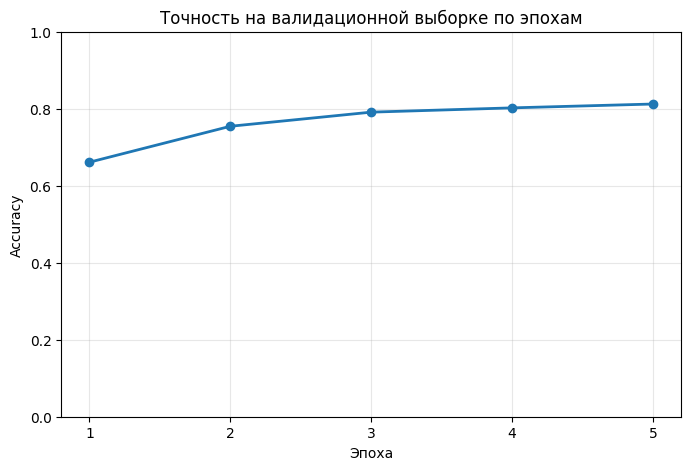

In [12]:
plt.figure(figsize=(8, 5))
plt.plot(history.epoch, history.valid_accuracy, marker='o', color='tab:blue', linewidth=2)
plt.title("Точность на валидационной выборке по эпохам")
plt.xlabel("Эпоха")
plt.ylabel("Accuracy")
plt.xticks(history.epoch)
plt.ylim(0.0, 1.0) # От 0 до 1
plt.grid(alpha=0.3)
plt.show()

### 9. Получите ответы на test

Часть `test` содержит по 100 изображений каждого выбранного класса.
В этом проходе нет `backward()` и `step()`.
Параметры модели не изменяются.

In [13]:
model.eval() # ОБЯЗАТЕЛЬНО!
all_preds = []
all_labels = []

with torch.no_grad(): # Отключаем вычисление градиентов
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)
        
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())

acc = accuracy_score(all_labels, all_preds)
print(f"Точность на тестовой выборке (Test Accuracy): {acc:.4f}")

Точность на тестовой выборке (Test Accuracy): 0.7989


### 10. Постройте матрицу ошибок и покажите три изображения

Для матрицы используйте `ConfusionMatrixDisplay.from_predictions`.
Передайте `answers`, `predictions`, `labels=range(3)` и `display_labels=class_names`.

Индексы первых ошибок находятся в `error_indices[:3]`.
Изображение с таким индексом можно получить как `test_data[index][0]`.
Для показа верните диапазон `0…1` выражением `image * 0.5 + 0.5` и переставьте оси через `permute(1, 2, 0)`.
Подпишите истинный класс и ответ модели.
Если ошибок меньше трёх, покажите все имеющиеся.

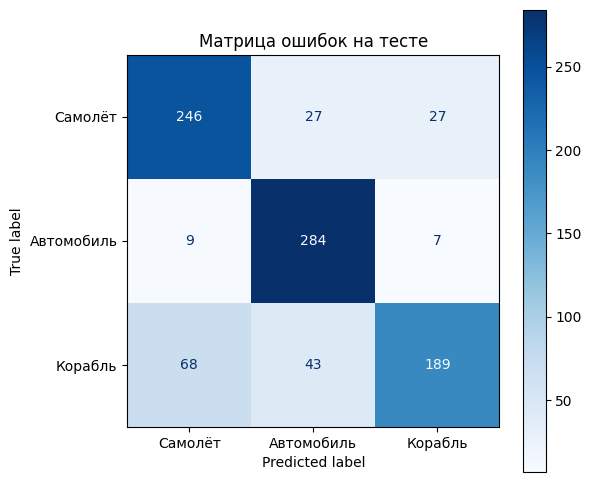

Всего ошибок: 181


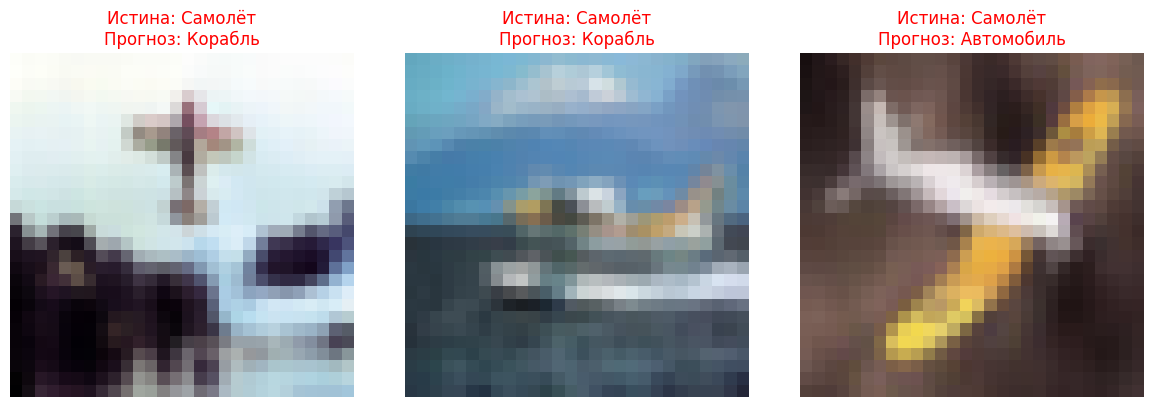

In [14]:
# 1. Матрица ошибок
fig, ax = plt.subplots(figsize=(6, 6))
ConfusionMatrixDisplay.from_predictions(
    all_labels, 
    all_preds, 
    labels=range(3), 
    display_labels=class_names,
    cmap="Blues",
    ax=ax
)
plt.title("Матрица ошибок на тесте")
plt.show()

# 2. Поиск ошибок
error_indices = [i for i, (l, p) in enumerate(zip(all_labels, all_preds)) if l != p]
print(f"Всего ошибок: {len(error_indices)}")

# Берем первые 3 ошибки (или меньше, если ошибок мало)
n_errors = min(3, len(error_indices))
if n_errors > 0:
    fig, axes = plt.subplots(1, n_errors, figsize=(12, 4))
    if n_errors == 1: axes = [axes] # Чтобы был итерируемый объект
    
    for i in range(n_errors):
        idx = error_indices[i]
        img_tensor, true_label = test_data[idx]
        pred_label = all_preds[idx]
        
        # Возвращаем картинку в нормальный диапазон 0...1 и меняем оси
        img_show = img_tensor * 0.5 + 0.5
        img_show = img_show.permute(1, 2, 0).numpy()
        
        axes[i].imshow(img_show)
        axes[i].axis('off')
        axes[i].set_title(f"Истина: {class_names[true_label]}\nПрогноз: {class_names[pred_label]}", color='red')
        
    plt.tight_layout()
    plt.show()
else:
    print("Модель не допустила ни одной ошибки на тесте!")